In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
classification_report,f1_score,auc)

import warnings
warnings.filterwarnings('ignore')


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
                                accuracy_score,
                                classification_report,
                                confusion_matrix )


In [3]:
df=pd.read_excel(r"C:\brijesh data\DryBeanDataset\Dry_Bean_Dataset.xlsx")
df

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [5]:
df.duplicated().sum()

np.int64(68)

In [6]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [7]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

In [8]:
df.drop_duplicates()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [9]:
df.duplicated().sum()

np.int64(68)

In [10]:
df = df.drop_duplicates()


In [11]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000
mean,53048.460385,854.993406,319.895602,202.365321,1.581075,0.750315,53767.986709,253.034094,0.749829,0.987152,0.873671,0.800352,0.006561,0.001719,0.644341,0.995078
std,29392.438324,214.722684,85.809260,45.051632,0.245245,0.091858,29844.248525,59.307709,0.048939,0.004650,0.059393,0.061464,0.001130,0.000595,0.098653,0.004347
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36282.500000,703.230000,253.086806,175.886357,1.430662,0.715144,36673.000000,214.933277,0.718735,0.985678,0.833410,0.763228,0.005893,0.001158,0.582517,0.993720
50%,44580.000000,793.896000,296.404589,192.491117,1.549860,0.763997,45122.000000,238.245711,0.759903,0.988288,0.883490,0.801514,0.006643,0.001700,0.642424,0.996393
75%,61382.000000,977.146500,376.312489,217.245403,1.703916,0.809671,62360.000000,279.560351,0.786849,0.990019,0.917031,0.834470,0.007270,0.002173,0.696341,0.997891
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [12]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [13]:
df.tail()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [14]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='str')

In [15]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

In [16]:
df['Class'] = df['Class'].astype('category')

In [17]:
df.dtypes

Area                  int64
Perimeter           float64
MajorAxisLength     float64
MinorAxisLength     float64
AspectRation        float64
Eccentricity        float64
ConvexArea            int64
EquivDiameter       float64
Extent              float64
Solidity            float64
roundness           float64
Compactness         float64
ShapeFactor1        float64
ShapeFactor2        float64
ShapeFactor3        float64
ShapeFactor4        float64
Class              category
dtype: object

In [18]:
df.nunique()

Area               12011
Perimeter          13416
MajorAxisLength    13543
MinorAxisLength    13543
AspectRation       13543
Eccentricity       13543
ConvexArea         12066
EquivDiameter      12011
Extent             13535
Solidity           13526
roundness          13543
Compactness        13543
ShapeFactor1       13543
ShapeFactor2       13543
ShapeFactor3       13543
ShapeFactor4       13543
Class                  7
dtype: int64

In [19]:
# checking the outliers 

In [20]:
df['Class'].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

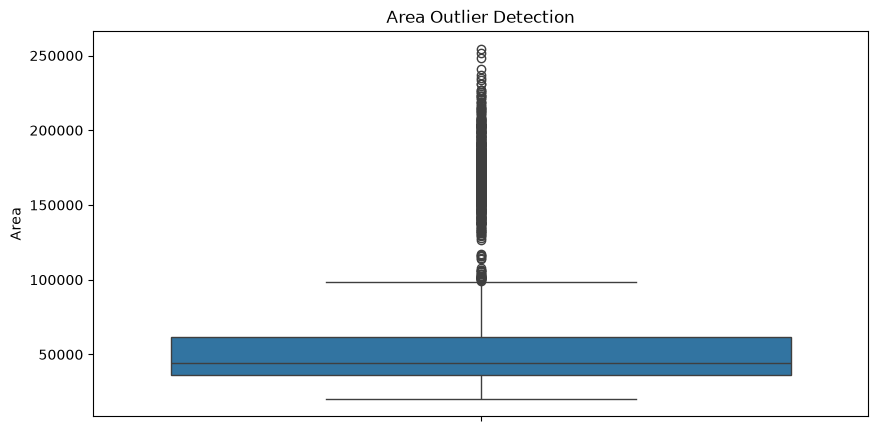

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(y=df['Area'])

plt.title('Area Outlier Detection')
plt.ylabel('Area')

plt.show()

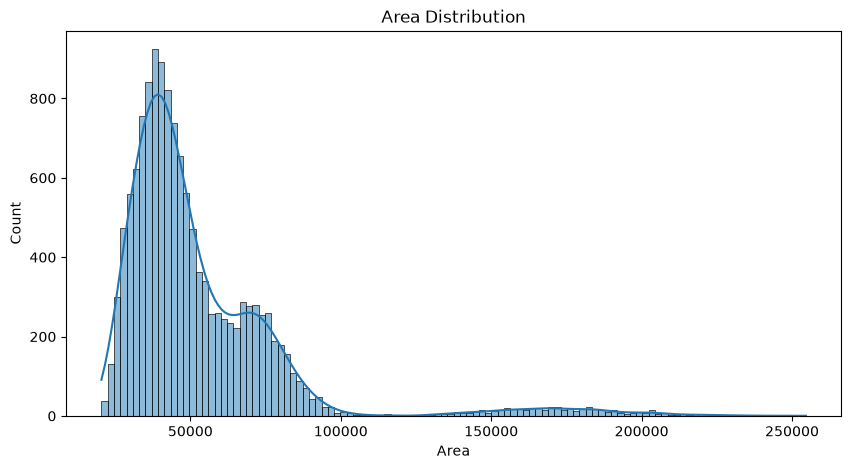

In [22]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Area'], kde=True)

plt.title('Area Distribution')
plt.show()

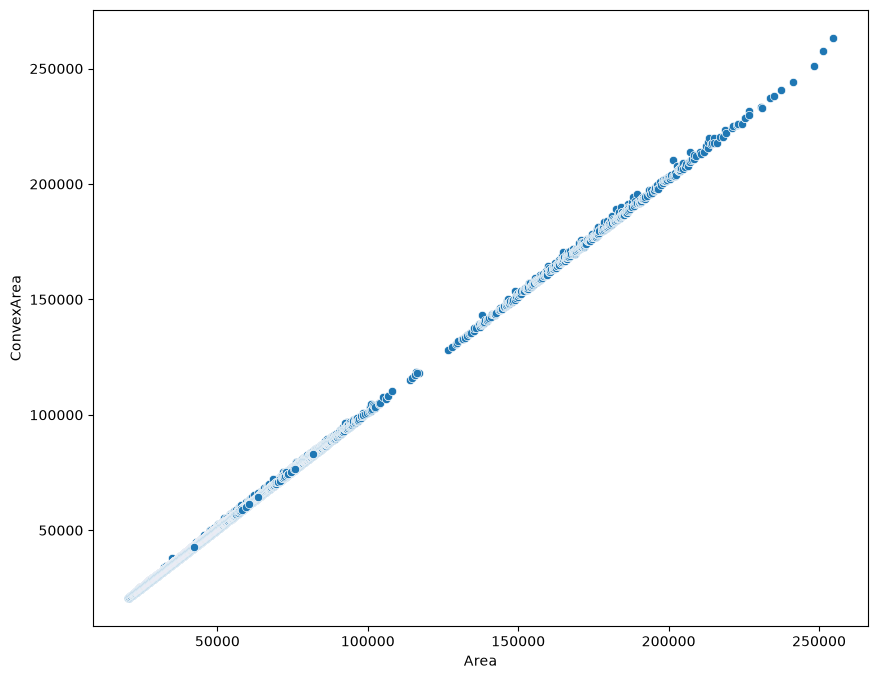

In [23]:
plt.figure(figsize=(10,8))
sns.scatterplot(x=df["Area"], y=df["ConvexArea"])
plt.show()

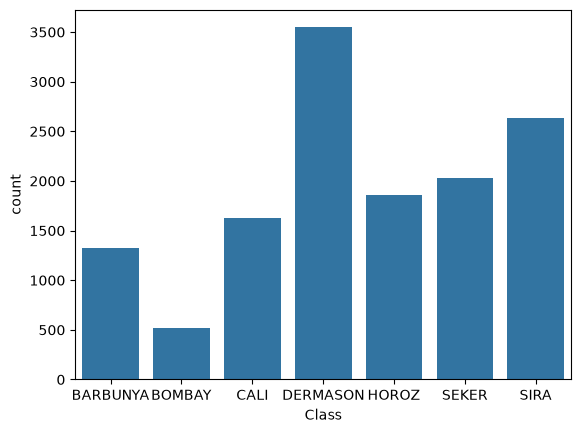

In [24]:
sns.countplot(data=df , x='Class')
plt.show()

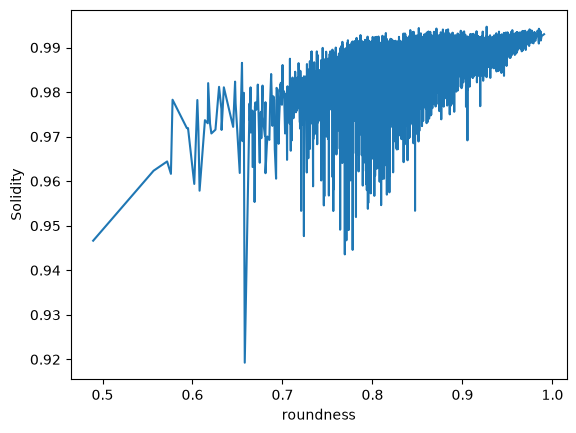

In [25]:
sns.lineplot(data=df, x="roundness", y="Solidity")
plt.show()

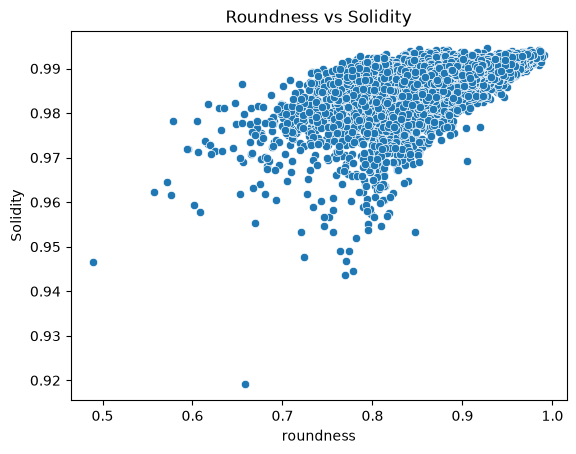

In [26]:
sns.scatterplot(data=df, x="roundness", y="Solidity")
plt.title("Roundness vs Solidity")
plt.show()

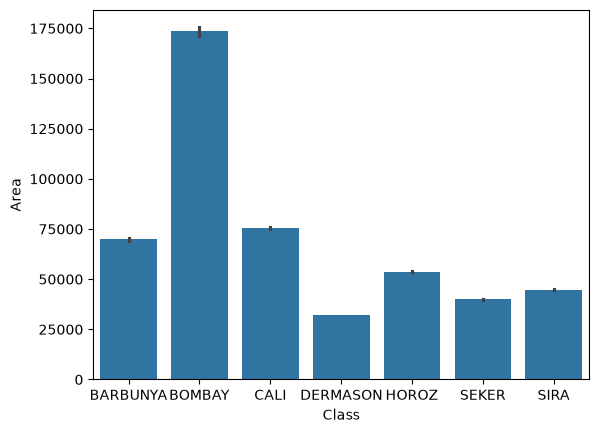

In [27]:
sns.barplot(data=df, x='Class',y='Area')
plt.show()

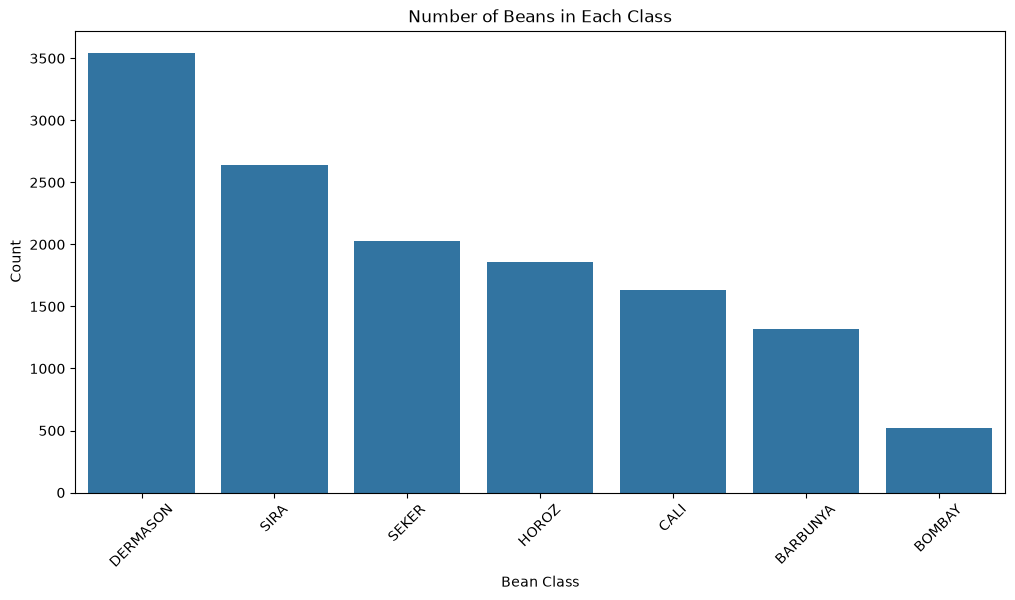

In [28]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='Class',
    order=df['Class'].value_counts().index
)

plt.title('Number of Beans in Each Class')
plt.xlabel('Bean Class')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

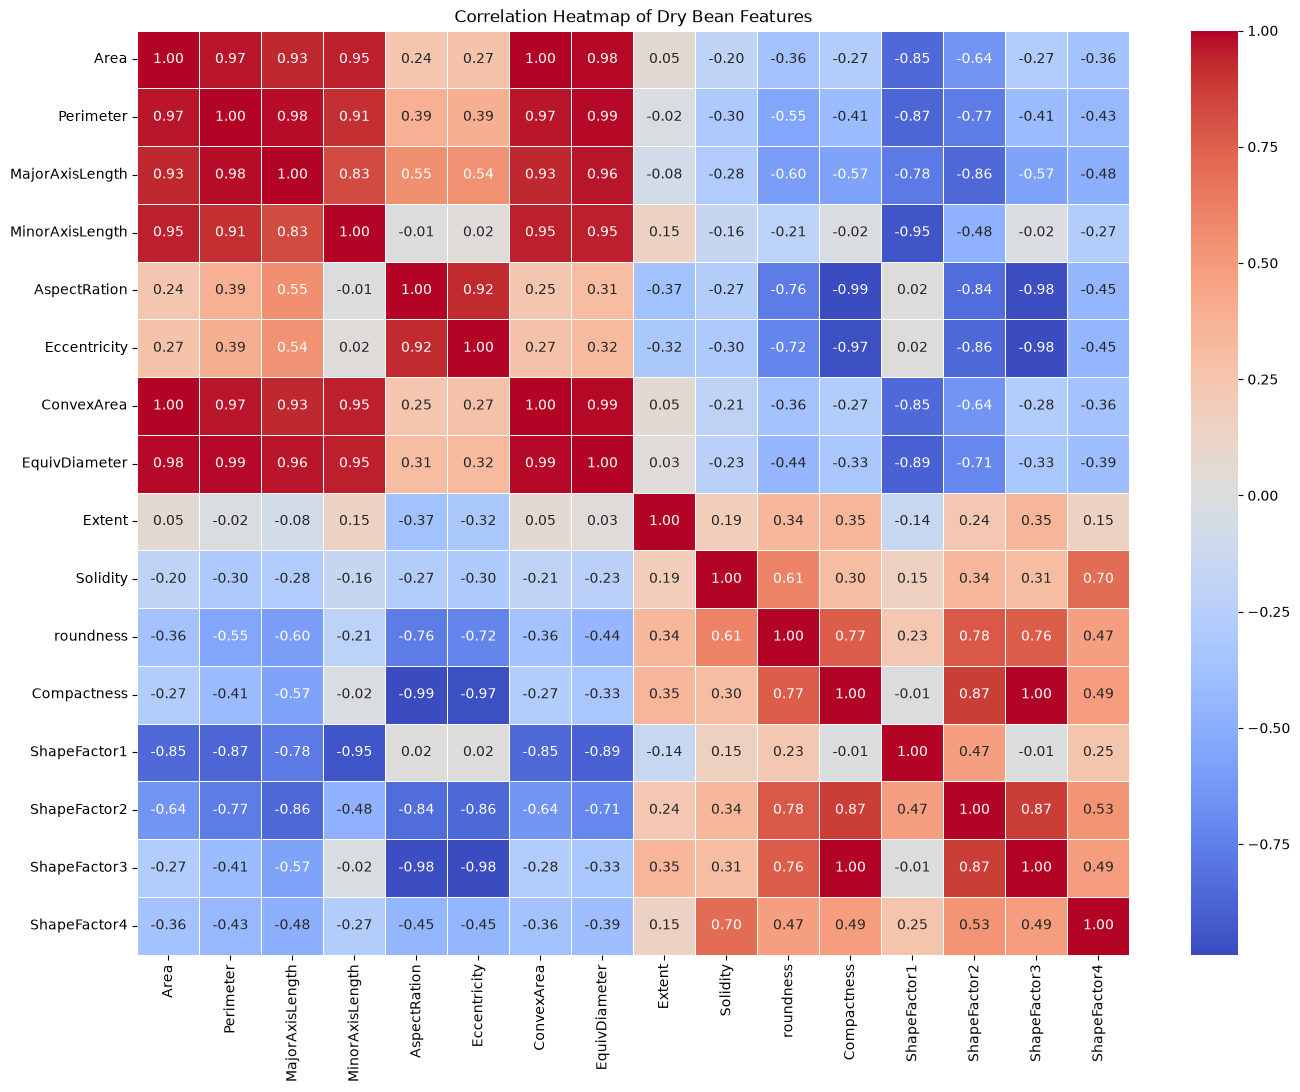

In [29]:
plt.figure(figsize=(16, 12))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Dry Bean Features')
plt.show()

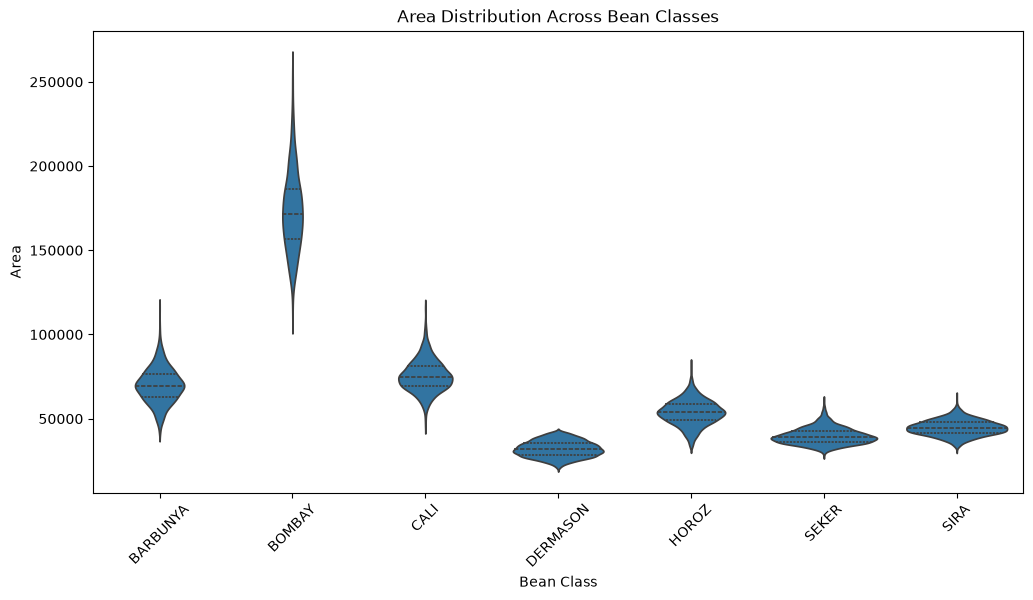

In [30]:
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x='Class',
    y='Area',
    inner='quartile'
)

plt.title('Area Distribution Across Bean Classes')
plt.xlabel('Bean Class')
plt.ylabel('Area')
plt.xticks(rotation=45)
plt.show()

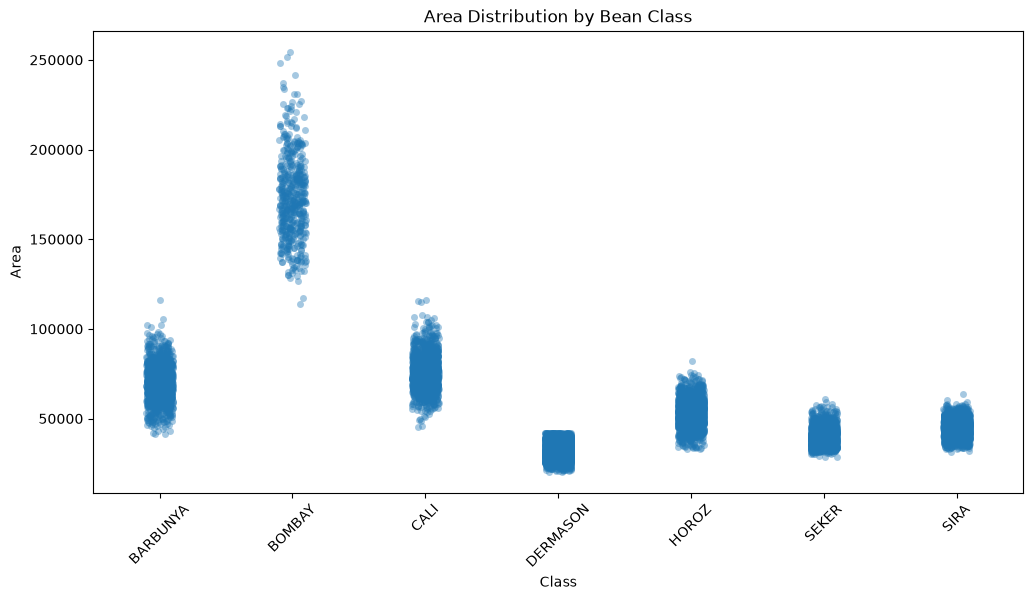

In [31]:
plt.figure(figsize=(12, 6))
sns.stripplot(data=df, x='Class', y='Area', jitter=True, alpha=0.4)
plt.title('Area Distribution by Bean Class')
plt.xticks(rotation=45)
plt.show()

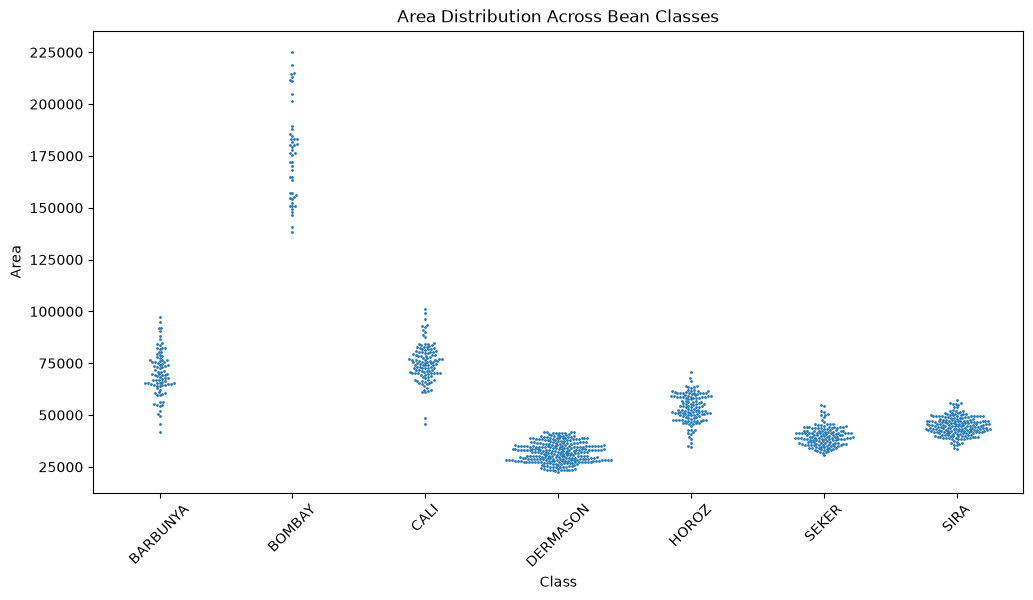

In [32]:
sample_df = df.sample(n=1000, random_state=42)

plt.figure(figsize=(12, 6))

sns.swarmplot(
    data=sample_df,
    x='Class',
    y='Area',
    size=2
)

plt.title('Area Distribution Across Bean Classes')
plt.xticks(rotation=45)
plt.show()

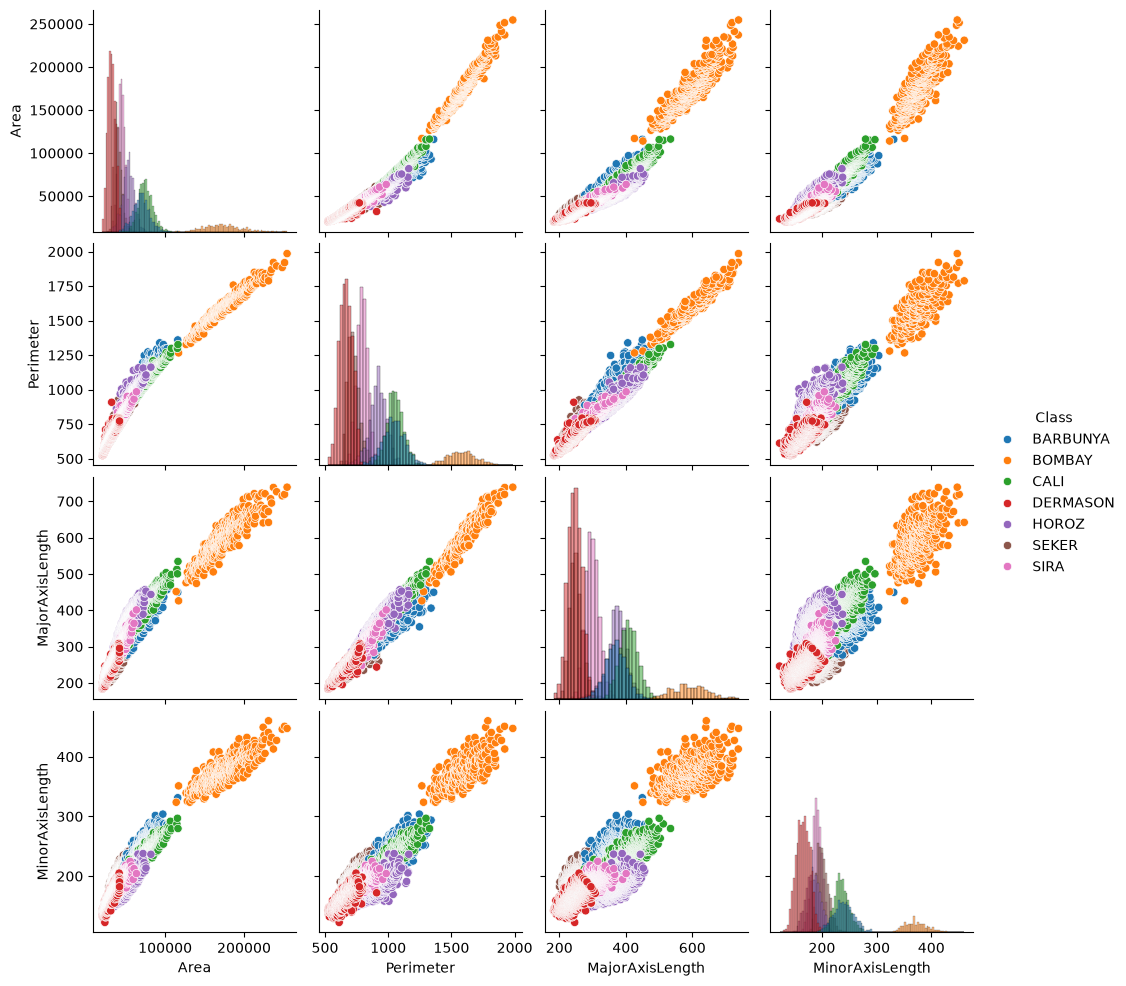

In [33]:
sns.pairplot(
    df,
    vars=['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength'],
    hue='Class',
    diag_kind='hist'
)
plt.show()

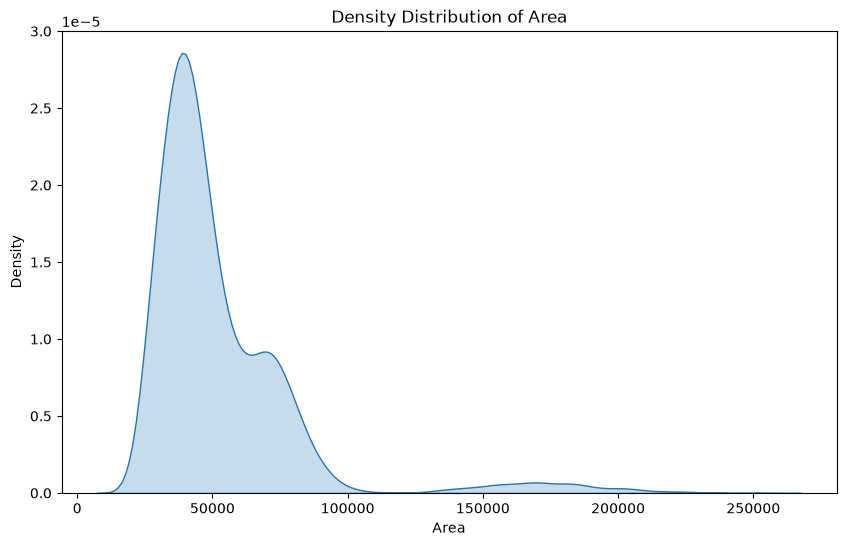

In [34]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='Area', fill=True)
plt.title('Density Distribution of Area')
plt.show()

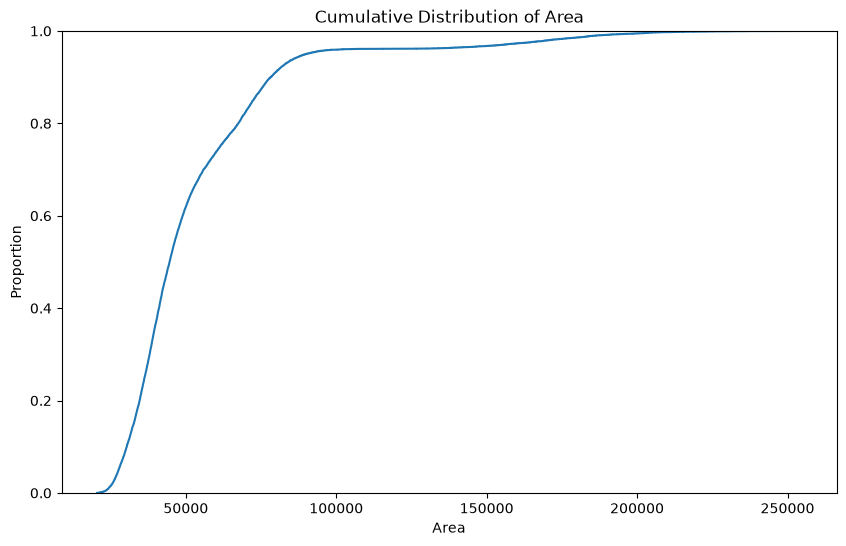

In [35]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=df, x='Area')
plt.title('Cumulative Distribution of Area')
plt.show()

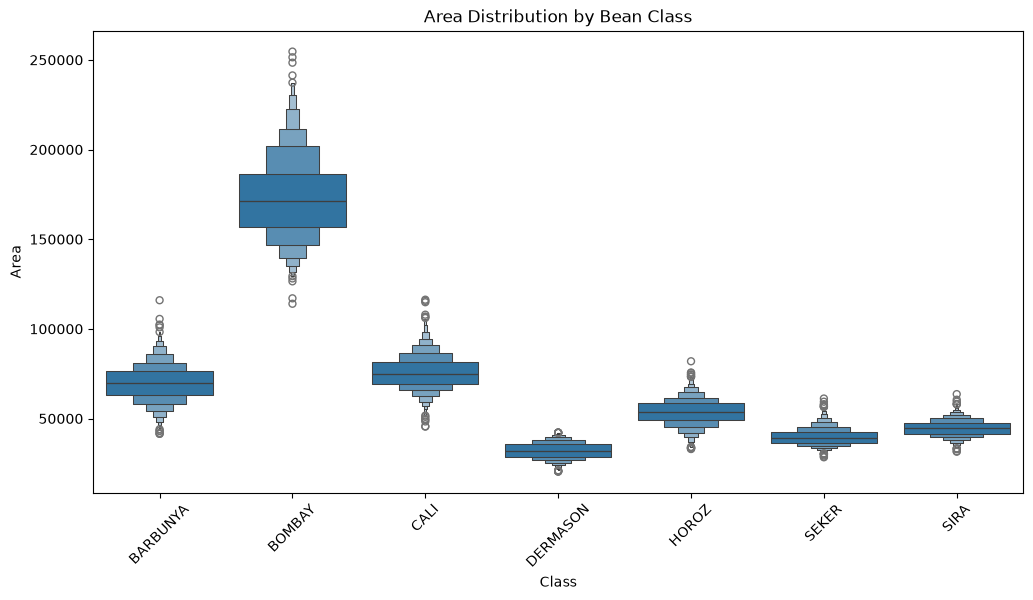

In [36]:
plt.figure(figsize=(12, 6))
sns.boxenplot(data=df, x='Class', y='Area')
plt.title('Area Distribution by Bean Class')
plt.xticks(rotation=45)
plt.show()

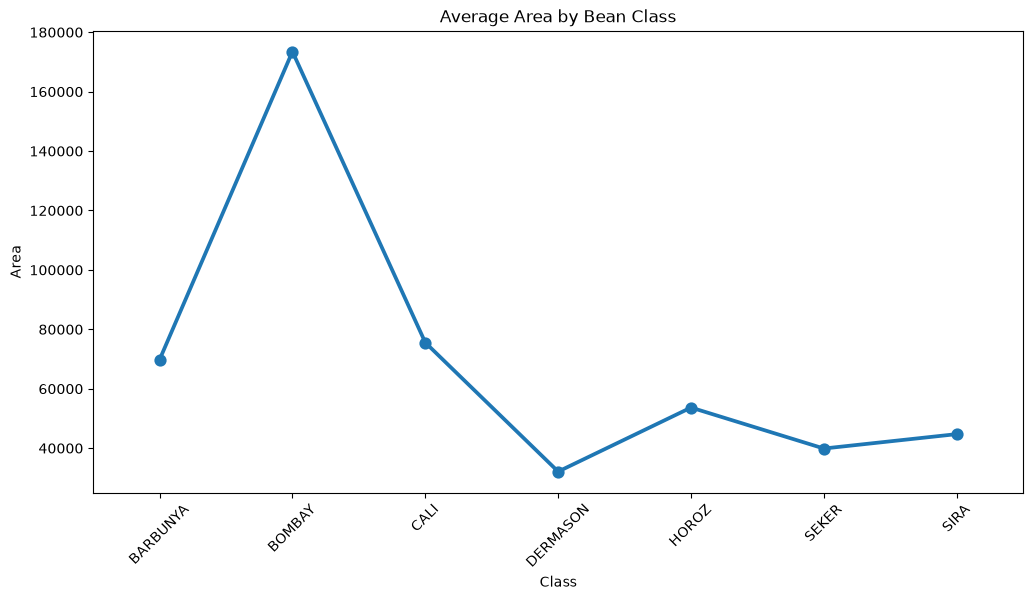

In [37]:
plt.figure(figsize=(12, 6))
sns.pointplot(data=df, x='Class', y='Area', errorbar=None)
plt.title('Average Area by Bean Class')
plt.xticks(rotation=45)
plt.show()

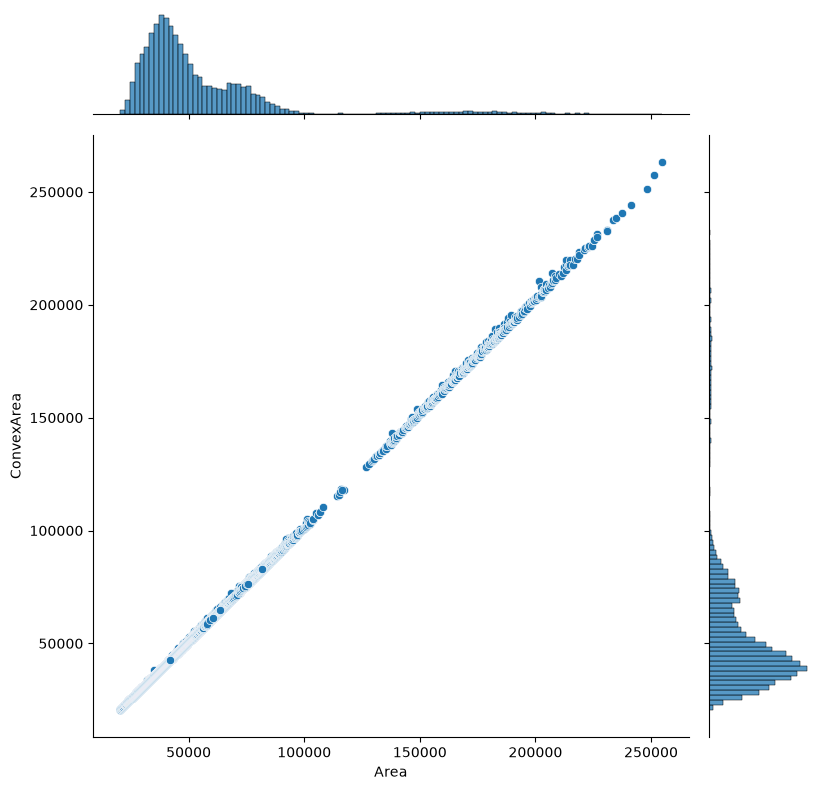

In [38]:
sns.jointplot(
    data=df,
    x='Area',
    y='ConvexArea',
    kind='scatter',
    height=8
)
plt.show()

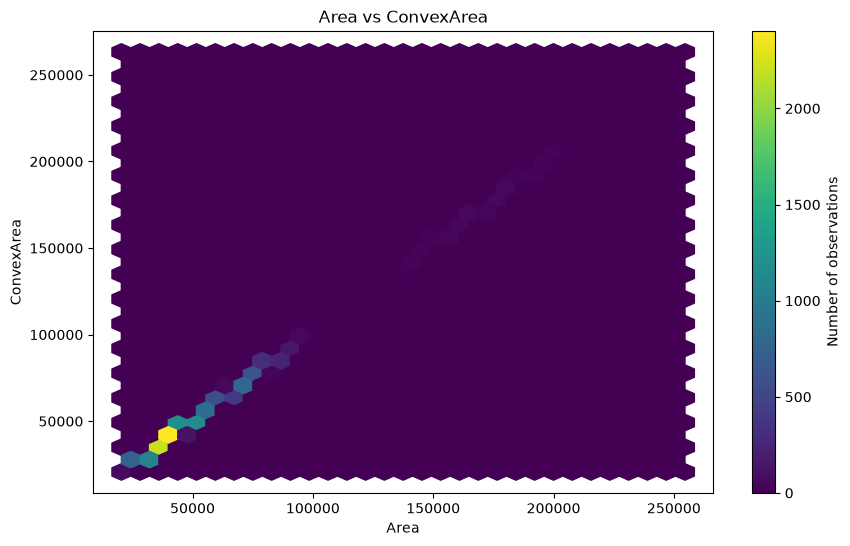

In [39]:
plt.figure(figsize=(10, 6))
plt.hexbin(df['Area'], df['ConvexArea'], gridsize=30, cmap='viridis')
plt.colorbar(label='Number of observations')
plt.title('Area vs ConvexArea')
plt.xlabel('Area')
plt.ylabel('ConvexArea')
plt.show()

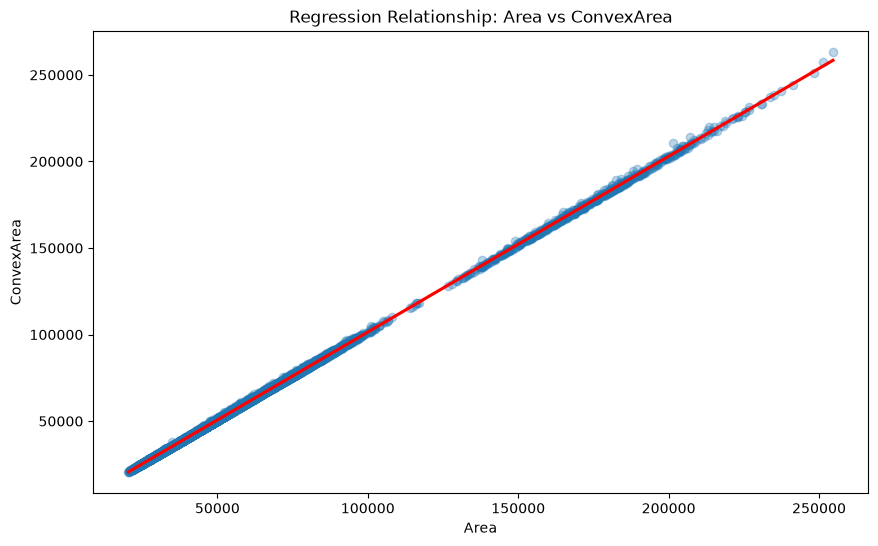

In [40]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df,
    x='Area',
    y='ConvexArea',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)
plt.title('Regression Relationship: Area vs ConvexArea')
plt.show()

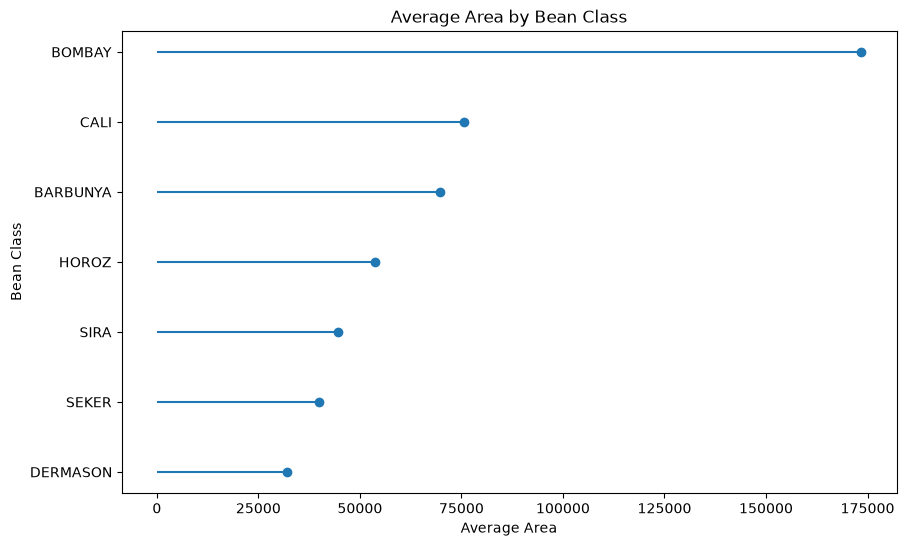

In [41]:
class_avg = df.groupby('Class', observed=True)['Area'].mean().sort_values()

plt.figure(figsize=(10, 6))
plt.hlines(
    y=class_avg.index,
    xmin=0,
    xmax=class_avg.values
)
plt.plot(class_avg.values, class_avg.index, 'o')
plt.title('Average Area by Bean Class')
plt.xlabel('Average Area')
plt.ylabel('Bean Class')
plt.show()

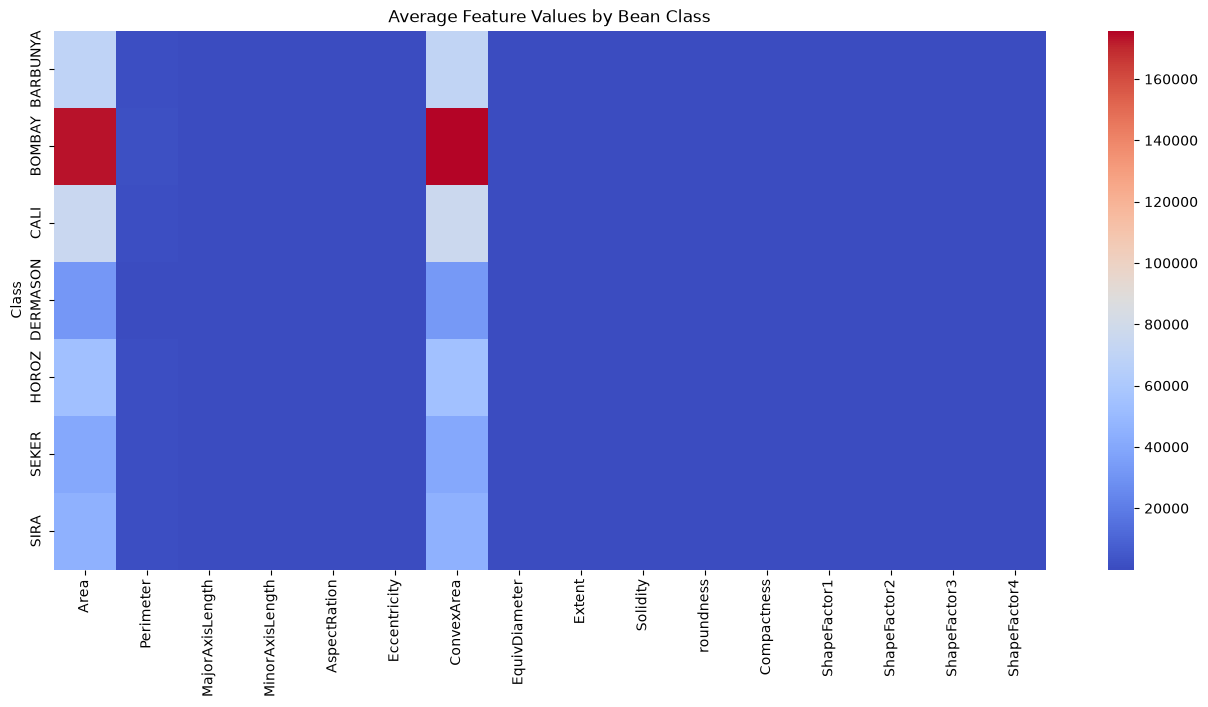

In [42]:
class_data = df.groupby('Class', observed=True).mean(numeric_only=True)

plt.figure(figsize=(16, 7))
sns.heatmap(class_data, cmap='coolwarm', annot=False)
plt.title('Average Feature Values by Bean Class')
plt.show()

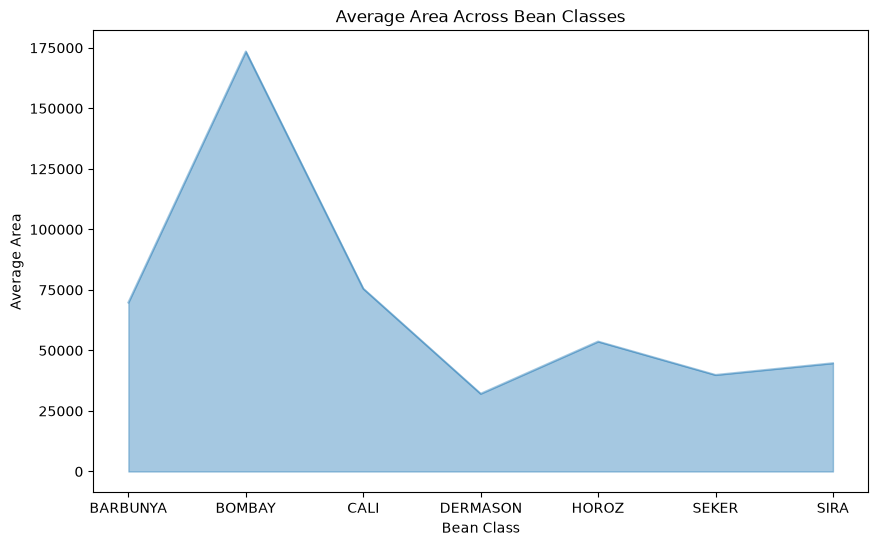

In [43]:
area_data = df.groupby('Class', observed=True)['Area'].mean()

plt.figure(figsize=(10, 6))
area_data.plot(kind='area', alpha=0.4)
plt.title('Average Area Across Bean Classes')
plt.xlabel('Bean Class')
plt.ylabel('Average Area')
plt.show()

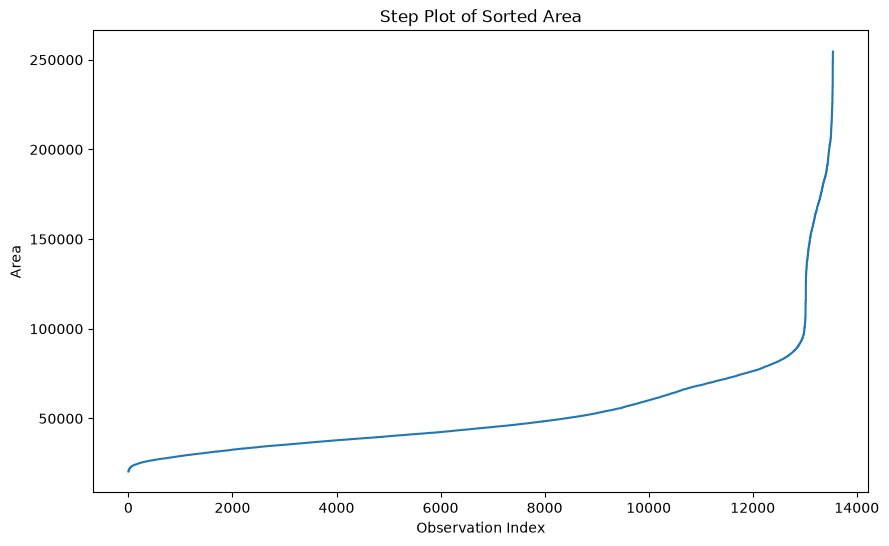

In [44]:
sorted_area = np.sort(df['Area'])

plt.figure(figsize=(10, 6))
plt.step(range(len(sorted_area)), sorted_area)
plt.title('Step Plot of Sorted Area')
plt.xlabel('Observation Index')
plt.ylabel('Area')
plt.show()

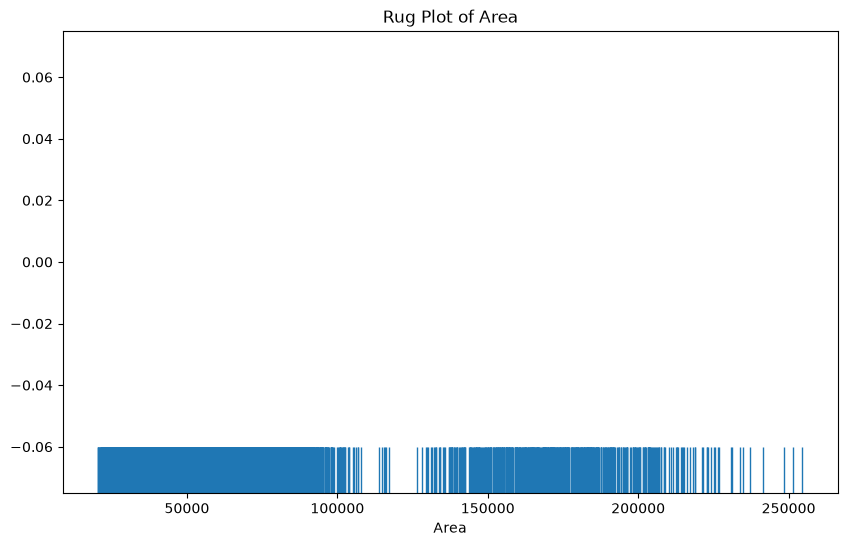

In [45]:
plt.figure(figsize=(10, 6))
sns.rugplot(data=df, x='Area', height=0.1)
plt.title('Rug Plot of Area')
plt.xlabel('Area')
plt.show()

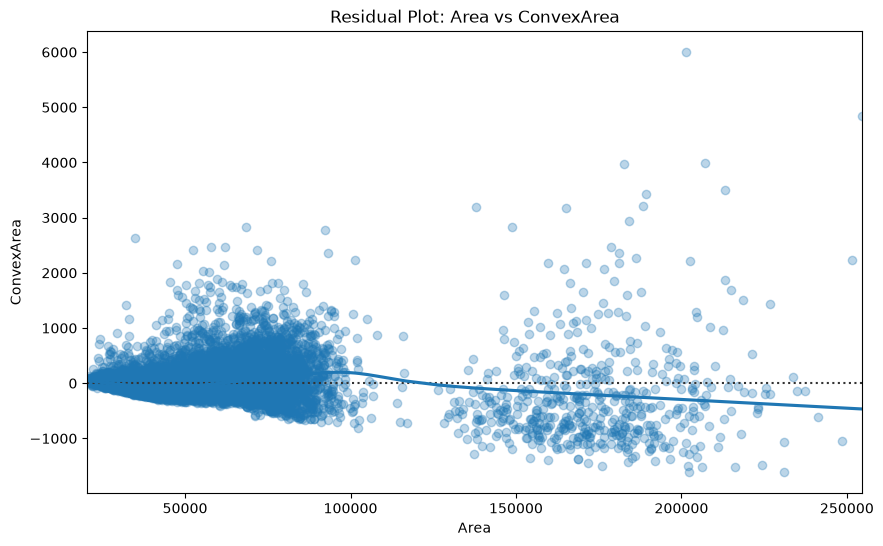

In [46]:
plt.figure(figsize=(10, 6))
sns.residplot(
    data=df,
    x='Area',
    y='ConvexArea',
    lowess=True,
    scatter_kws={'alpha': 0.3}
)
plt.title('Residual Plot: Area vs ConvexArea')
plt.show()

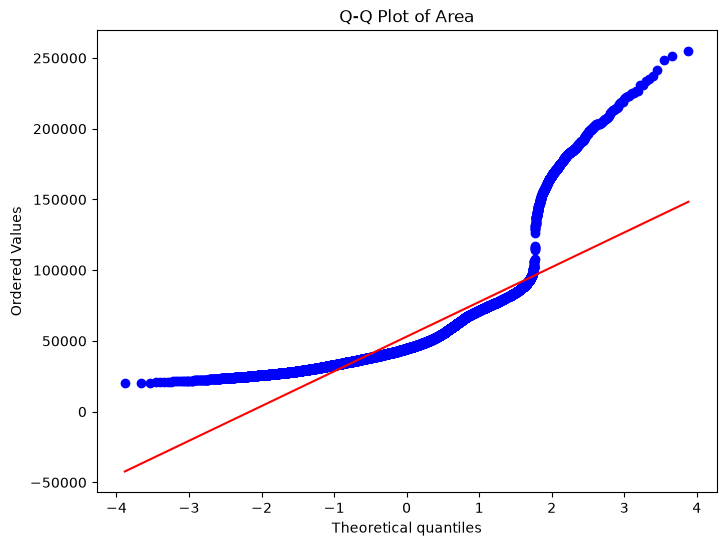

In [47]:
import scipy.stats as stats

plt.figure(figsize=(8, 6))
stats.probplot(df['Area'], dist='norm', plot=plt)
plt.title('Q-Q Plot of Area')
plt.show()

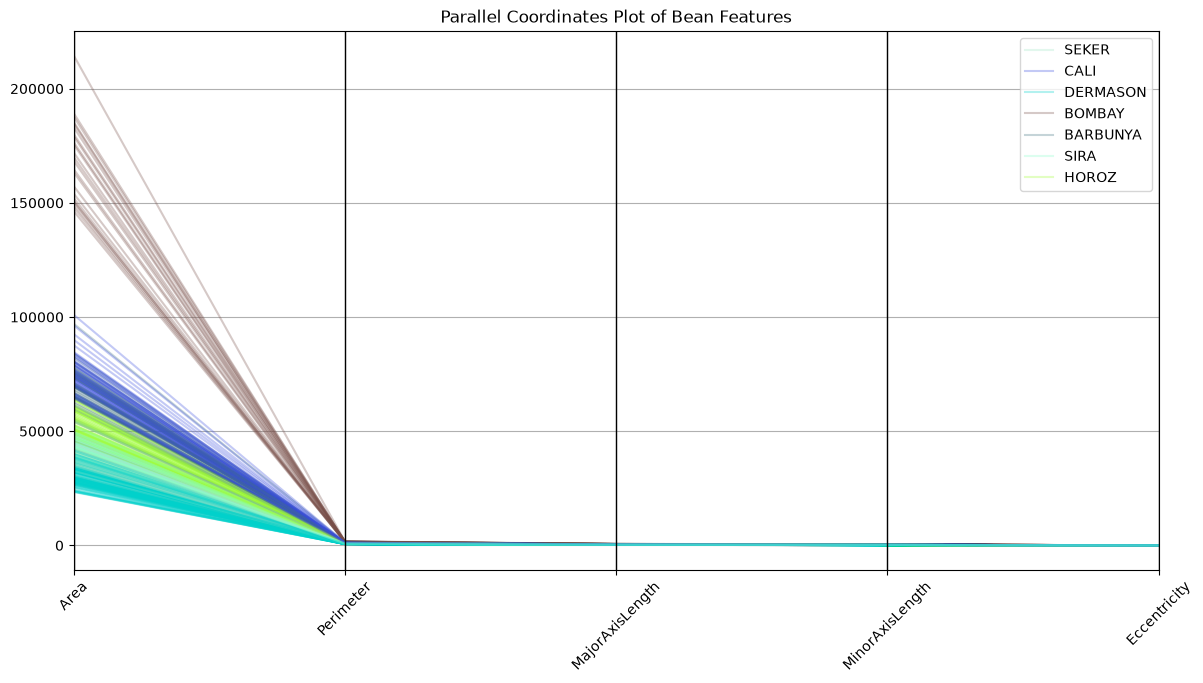

In [48]:
from pandas.plotting import parallel_coordinates

sample_df = df[
    ['Class', 'Area', 'Perimeter', 'MajorAxisLength',
     'MinorAxisLength', 'Eccentricity']
].sample(n=500, random_state=42)

plt.figure(figsize=(14, 7))
parallel_coordinates(sample_df, 'Class', alpha=0.3)
plt.title('Parallel Coordinates Plot of Bean Features')
plt.xticks(rotation=45)
plt.show()

In [49]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [50]:
x=df.drop(['Class'],axis=1)
y=df['Class']
x.shape,y.shape

((13543, 16), (13543,))

In [51]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)

In [53]:
x=pd.DataFrame(x_scaled,columns=x.columns)
x

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,0.034053,0.058574,0.044262,0.152142,0.122612,0.477797,0.033107,0.070804,0.671024,0.922824,0.934823,0.786733,0.593432,0.833049,0.750996,0.980620
1,0.035500,0.077557,0.030479,0.178337,0.051577,0.278472,0.034991,0.073577,0.735504,0.871514,0.793138,0.903549,0.547447,0.967315,0.884987,0.974979
2,0.038259,0.068035,0.052633,0.158190,0.131521,0.496448,0.037126,0.078816,0.716671,0.932141,0.914511,0.773514,0.582016,0.800942,0.736200,0.987196
3,0.040940,0.082942,0.048548,0.177691,0.091623,0.403864,0.041389,0.083854,0.731365,0.761614,0.826871,0.829912,0.552408,0.854744,0.799846,0.893675
4,0.041504,0.065313,0.032862,0.200679,0.025565,0.165680,0.040123,0.084906,0.700538,0.949832,0.988408,0.951583,0.510741,1.000000,0.941770,0.989116
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13538,0.092559,0.160862,0.189318,0.187843,0.375584,0.788553,0.089967,0.172180,0.512286,0.942381,0.852151,0.465175,0.531785,0.382135,0.412185,0.974113
13539,0.092576,0.159358,0.176450,0.201964,0.321303,0.746241,0.089910,0.172207,0.786890,0.947954,0.862952,0.523974,0.509582,0.426233,0.470848,0.970912
13540,0.092739,0.160605,0.176384,0.203370,0.318558,0.743877,0.090219,0.172463,0.561689,0.936648,0.855785,0.525351,0.508683,0.427019,0.472240,0.943025
13541,0.092773,0.163657,0.179703,0.200669,0.330472,0.753971,0.090623,0.172517,0.482741,0.908991,0.834795,0.510145,0.514216,0.415330,0.456919,0.913342


In [54]:
x_train,x_test,y_train,y_test = train_test_split(x,y ,random_state=56)

In [55]:
from sklearn.neighbors import KNeighborsClassifier as KNN
from sklearn.metrics import f1_score,classification_report

In [56]:
knn=KNN()
knn.fit(x_train,y_train)
y_pre=knn.predict(x_test)
print(classification_report(y_test,y_pre))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.88      0.91       365
      BOMBAY       1.00      1.00      1.00       116
        CALI       0.92      0.94      0.93       396
    DERMASON       0.92      0.91      0.91       884
       HOROZ       0.96      0.95      0.95       459
       SEKER       0.95      0.93      0.94       504
        SIRA       0.84      0.88      0.86       662

    accuracy                           0.92      3386
   macro avg       0.93      0.93      0.93      3386
weighted avg       0.92      0.92      0.92      3386



In [57]:
knn=KNN(n_neighbors=1)
knn.fit(x_train,y_train)
y_pre=knn.predict(x_test)
print(classification_report(y_test,y_pre))

              precision    recall  f1-score   support

    BARBUNYA       0.88      0.88      0.88       365
      BOMBAY       1.00      1.00      1.00       116
        CALI       0.91      0.91      0.91       396
    DERMASON       0.90      0.90      0.90       884
       HOROZ       0.93      0.93      0.93       459
       SEKER       0.94      0.92      0.93       504
        SIRA       0.82      0.83      0.82       662

    accuracy                           0.90      3386
   macro avg       0.91      0.91      0.91      3386
weighted avg       0.90      0.90      0.90      3386



In [59]:
for c in [1, 6]:
    knn = KNN(n_neighbors=5)
    knn.fit(x_train,y_train)
    y_pre=knn.predict(x_test)
    print(classification_report(y_test,y_pre))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.88      0.91       365
      BOMBAY       1.00      1.00      1.00       116
        CALI       0.92      0.94      0.93       396
    DERMASON       0.92      0.91      0.91       884
       HOROZ       0.96      0.95      0.95       459
       SEKER       0.95      0.93      0.94       504
        SIRA       0.84      0.88      0.86       662

    accuracy                           0.92      3386
   macro avg       0.93      0.93      0.93      3386
weighted avg       0.92      0.92      0.92      3386

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.88      0.91       365
      BOMBAY       1.00      1.00      1.00       116
        CALI       0.92      0.94      0.93       396
    DERMASON       0.92      0.91      0.91       884
       HOROZ       0.96      0.95      0.95       459
       SEKER       0.95      0.93      0.94       504
        SIRA       0.84 